## 1. Data loading

In [ ]:
import os
import numpy as np
import pandas as pd

CSV_NAME = 'output.csv'

df_raw = pd.read_csv(CSV_NAME)
print(f'Raw dataset: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns')

Raw dataset: 3078 rows, 4 columns


## 2. Data cleaning

### 2.1 Initial inspection

In [ ]:
display(df_raw.head())
df_raw.info()
print('\nUnique values per column:')
print(df_raw.nunique())

,no.,seat,school,candidate
0,1,president,SBS,'Will Iha'
1,2,president,SBS,'Will Iha'
2,3,president,SBS,'Will Iha'
3,4,president,SBS,'Will Iha'
4,5,president,SBS,'Will Iha'


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3078 entries, 0 to 3077
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   no.        3078 non-null   int64 
 1   seat       3078 non-null   object
 2   school     3078 non-null   object
 3   candidate  3078 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.3+ KB

Unique values per column:
no.          3078
seat            9
school          7
candidate      25
dtype: int64


The following issues were found:
- no. row is just an index row
- candidate name wrapped in '' ('Will Iha')
- each seat has different, specific candidates


### 2.2 Cleaning steps and checks

In [ ]:
df = df_raw.drop(columns='no.')
for col in ['seat', 'school', 'candidate']:
    df[col] = df[col].str.strip().str.strip("'\"")

seat_school = pd.crosstab(df['seat'], df['school'])

print('Missing values:', df.isna().sum().sum())
print('Rows identical to an earlier row:', df.duplicated().sum())
print('Candidates listed under more than one seat:', (df.groupby('candidate')['seat'].nunique() > 1).sum())
print('Votes per seat:', df['seat'].value_counts().unique().tolist())
print('School mix identical in every seat:', bool((seat_school.nunique() == 1).all()))
print(f'\nRows before: {len(df_raw)} | rows after: {len(df)} | columns: {list(df.columns)}')
df.head()

Missing values: 0
Rows identical to an earlier row: 2907
Candidates listed under more than one seat: 0
Votes per seat: [342]
School mix identical in every seat: True

Rows before: 3078 | rows after: 3078 | columns: ['seat', 'school', 'candidate']


,seat,school,candidate
0,president,SBS,Will Iha
1,president,SBS,Will Iha
2,president,SBS,Will Iha
3,president,SBS,Will Iha
4,president,SBS,Will Iha


- No missing values were found and no rows were removed.
- Every seat has 342 votes with an identical school mix, so the data comes from 342 respondents who each voted in all 9 seats.
- Each candidate belongs to exactly one seat, so no labels were mistyped across seats.
- The 2,907 identical rows are expected (one row per vote) and were kept.

### 2.3 Final dataset for modelling

In [ ]:
SEATS = list(dict.fromkeys(df['seat']))
SCHOOLS = sorted(df['school'].unique())
N = df['seat'].value_counts().iloc[0]

def votes(seat):
    return df[df['seat'] == seat]

datasets = {seat: (votes(seat)[['school']], votes(seat)['candidate']) for seat in SEATS}

pd.DataFrame({seat: {'rows': len(y), 'candidates': y.nunique(), 'smallest_class': y.value_counts().min()}
              for seat, (X, y) in datasets.items()}).T

,rows,candidates,smallest_class
president,342,4,35
vice_president,342,2,142
secretary_general,342,2,47
public_relations,342,3,81
finance,342,2,158
male_academic,342,4,26
female_academic,342,3,73
female_sports,342,3,72
male_sports,342,2,127


In [ ]:
pd.get_dummies(df[['school']].drop_duplicates().sort_values('school'), dtype=int).set_index(pd.Index(SCHOOLS, name='school'))

,school_SBS,school_SCES,school_SHSS,school_SI,school_SIMS,school_SLS,school_STH
school,,,,,,,
SBS,1,0,0,0,0,0,0
SCES,0,1,0,0,0,0,0
SHSS,0,0,1,0,0,0,0
SI,0,0,0,1,0,0,0
SIMS,0,0,0,0,1,0,0
SLS,0,0,0,0,0,1,0
STH,0,0,0,0,0,0,1


The modelling data is nine datasets, one per seat, each with 342 rows. The input is `school`, one-hot encoded into seven 0/1 columns (shown above) so that no artificial order is implied between schools. The target is `candidate`. The encoding is applied inside the model pipeline (section 4), so it is learnt from training data only.

## 3. Exploratory data analysis

In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

plt.rcParams.update({'font.family': 'serif', 'figure.dpi': 110})
GREYS = ['0.15', '0.45', '0.70', '0.92']
HATCHES = ['', '//', '..', 'xx']

### Observation 1: SCES dominates the sample

In [ ]:
composition = votes(SEATS[0])['school'].value_counts().to_frame('respondents')
composition['share_%'] = (100 * composition['respondents'] / N).round(1)
composition

,respondents,share_%
school,,
SCES,158,46.2
SBS,49,14.3
SHSS,48,14.0
SI,31,9.1
SIMS,24,7.0
SLS,20,5.8
STH,12,3.5


SCES supplies 46.2% of respondents, more than three times any other school, while STH, SLS and SIMS have only 12 to 24 each. The sample is assumed to represent the student population; if it does not, results lean towards SCES preferences.

### Observation 2: Every seat has a leader, but two races are close

In [ ]:
rows = []
for seat in SEATS:
    s = votes(seat)['candidate'].value_counts(normalize=True) * 100
    rows.append({'seat': seat, 'leader': s.index[0], 'leader_%': s.iloc[0],
                 'runner_up': s.index[1], 'runner_up_%': s.iloc[1], 'margin_pts': s.iloc[0] - s.iloc[1]})
pd.DataFrame(rows).set_index('seat').round(1)

,leader,leader_%,runner_up,runner_up_%,margin_pts
seat,,,,,
president,Will Iha,44.2,Sajjad Harunany,30.4,13.7
vice_president,Fidel Otieno,58.5,Cecilia Beverly,41.5,17.0
secretary_general,Fateema Abdul,86.3,No Confidence,13.7,72.5
public_relations,Sky Nderitu,45.3,Julie Jeptoo,31.0,14.3
finance,Caleb Mumo,53.8,Mark Mwai,46.2,7.6
male_academic,Moses Maingi,43.6,Ibrahim Maina,40.4,3.2
female_academic,Shania Omolo,55.6,Angela Mugwima,23.1,32.5
female_sports,Chadya Kendi,48.0,Irene Maithya,31.0,17.0
male_sports,Michael Karani,62.9,Jok Deng,37.1,25.7


Margins range from 72.5 points (Secretary General) to 3.2 points (Male Academic). Finance (7.6 points) and Male Academic are close enough that sampling error alone could reverse them.

### Observation 3: Many school-candidate groups are very small

In [ ]:
cells = (df[['seat', 'candidate']].drop_duplicates()
         .merge(pd.DataFrame({'school': SCHOOLS}), how='cross')
         .merge(df.groupby(['seat', 'school', 'candidate']).size().rename('votes').reset_index(), how='left')
         .fillna({'votes': 0})
         .astype({'votes': int}))
print(f"Seat-school-candidate groups: {len(cells)} | zero votes: {(cells['votes'] == 0).sum()} | "
      f"fewer than 5 votes: {(cells['votes'] < 5).sum()}")
cells[cells['votes'] == 0]

Seat-school-candidate groups: 175 | zero votes: 4 | fewer than 5 votes: 41


,seat,candidate,school,votes
27,president,Serge Kapongo,STH,0
34,vice_president,Fidel Otieno,STH,0
109,male_academic,Stephan Mari,SIMS,0
112,male_academic,Ayden Arodi,SBS,0


Four groups are empty and 41 of 175 have fewer than 5 votes, mostly in STH, SLS and SIMS. Without regularisation, coefficients for empty groups diverge to infinity and those for small groups are unstable. This motivates the regularisation in section 4.

### Observation 4: School is only weakly related to candidate choice

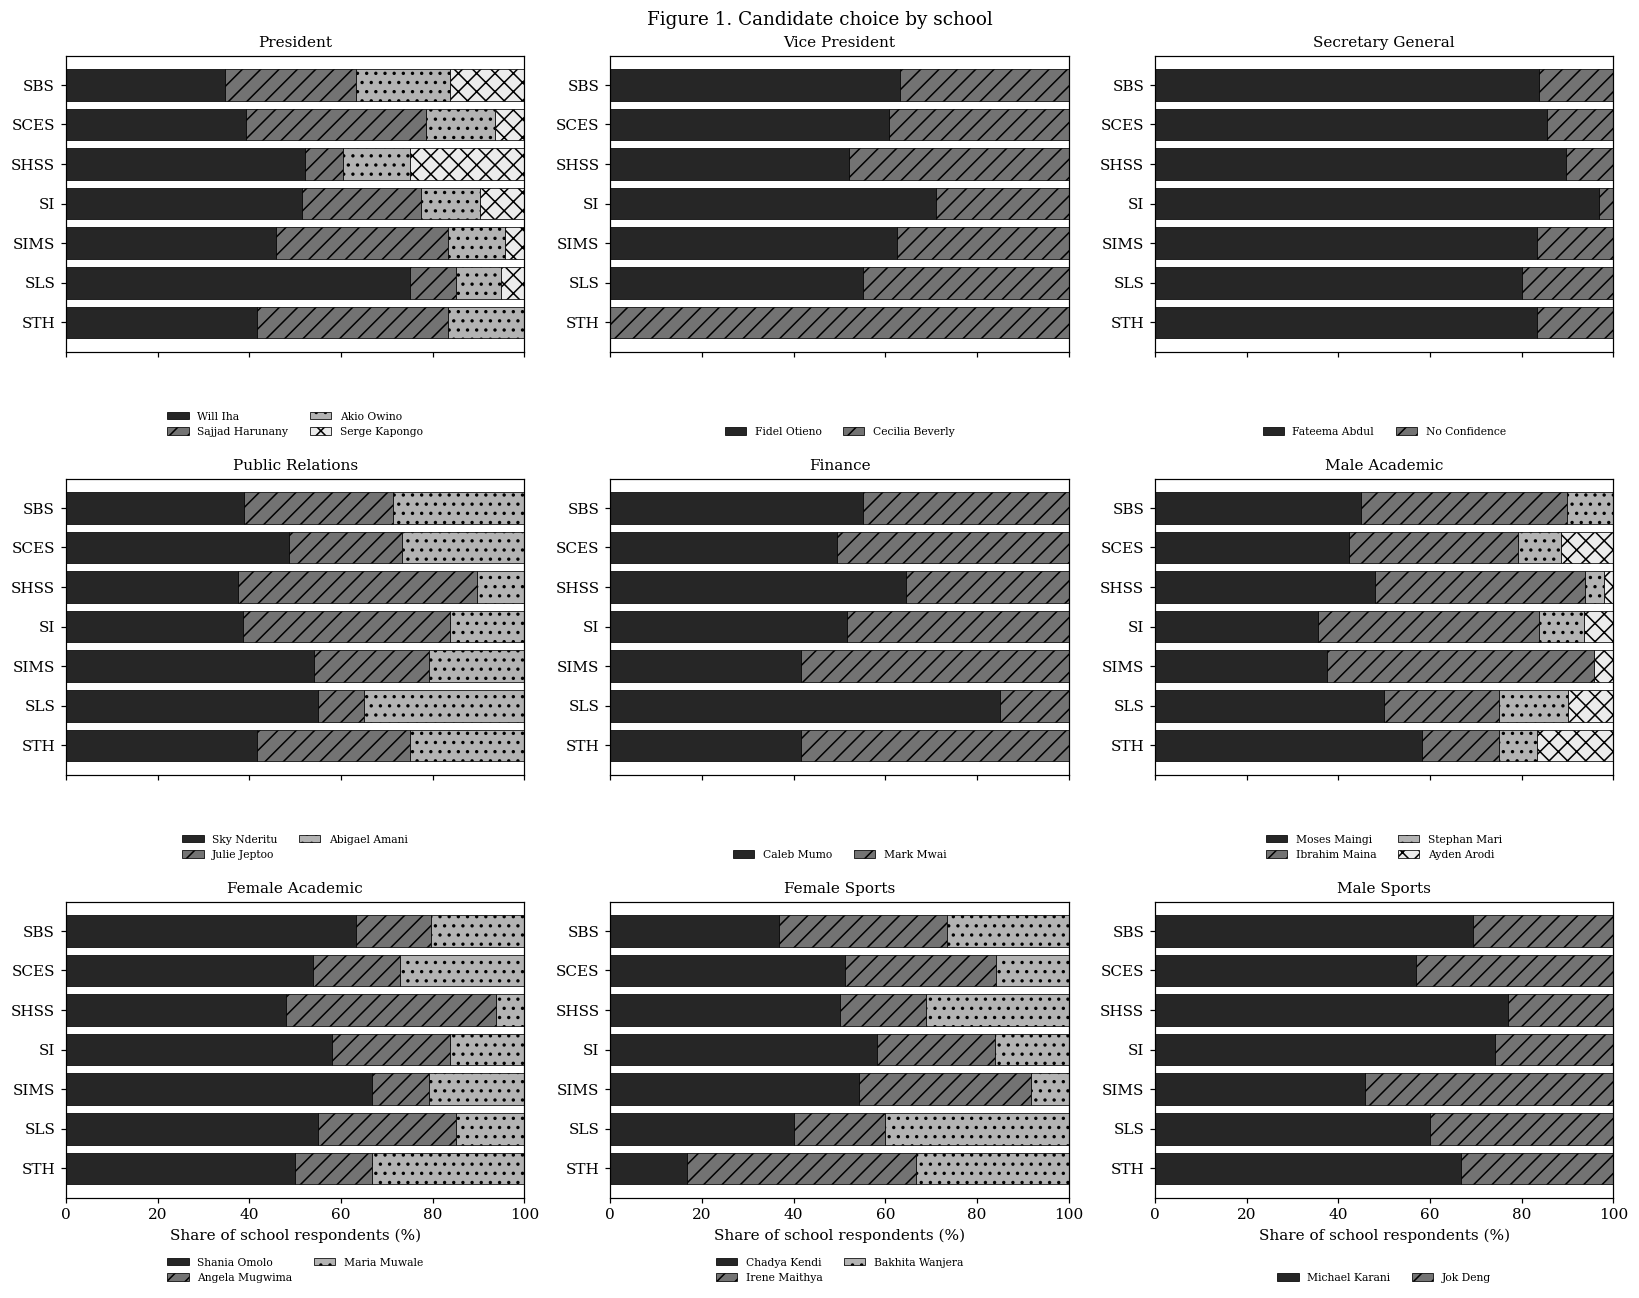

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12), sharex=True)
for ax, seat in zip(axes.flat, SEATS):
    d = votes(seat)
    order = d['candidate'].value_counts().index
    pct = pd.crosstab(d['school'], d['candidate'], normalize='index')[order] * 100
    left = np.zeros(len(pct))
    for i, cand in enumerate(order):
        ax.barh(pct.index, pct[cand], left=left, color=GREYS[i], hatch=HATCHES[i],
                edgecolor='black', linewidth=0.5, label=cand)
        left += pct[cand].to_numpy()
    ax.set_title(seat.replace('_', ' ').title(), fontsize=10)
    ax.set_xlim(0, 100)
    ax.invert_yaxis()
    ax.legend(fontsize=7, loc='lower center', bbox_to_anchor=(0.5, -0.32), ncol=2, frameon=False)
for ax in axes[-1]:
    ax.set_xlabel('Share of school respondents (%)')
fig.suptitle('Figure 1. Candidate choice by school', fontsize=12)
plt.tight_layout()
plt.show()

Chi-square test of independence per seat. P-values are estimated by permutation (many expected counts are below 5) and Holm-adjusted for the nine tests. Cramér's V measures strength (0 = none, 1 = perfect).

In [ ]:
def chi2_stat(t):
    e = t.sum(1, keepdims=True) * t.sum(0, keepdims=True) / t.sum()
    return ((t - e) ** 2 / e).sum()

rng = np.random.default_rng(42)
rows = []
for seat in SEATS:
    d = votes(seat)
    table = pd.crosstab(d['school'], d['candidate'])
    chi2 = chi2_contingency(table, correction=False)[0]
    s = pd.Categorical(d['school'], categories=table.index).codes
    c = pd.Categorical(d['candidate'], categories=table.columns).codes
    hits = 0
    for _ in range(10_000):
        t = np.zeros(table.shape)
        np.add.at(t, (s, rng.permutation(c)), 1)
        hits += chi2_stat(t) >= chi2 - 1e-9
    rows.append({'seat': seat, 'chi2': chi2, 'p_value': (hits + 1) / 10_001,
                 'cramers_v': np.sqrt(chi2 / (len(d) * (min(table.shape) - 1)))})

assoc = pd.DataFrame(rows).set_index('seat')
ranked = assoc['p_value'].sort_values()
assoc['p_holm'] = (ranked * np.arange(len(ranked), 0, -1)).cummax().clip(upper=1)
assoc['significant'] = assoc['p_holm'] < 0.05
assoc.round(3)

,chi2,p_value,cramers_v,p_holm,significant
seat,,,,,
president,41.401,0.002,0.201,0.016,True
vice_president,20.761,0.002,0.246,0.016,True
secretary_general,4.625,0.603,0.116,0.603,False
public_relations,23.333,0.026,0.185,0.154,False
finance,13.553,0.031,0.199,0.154,False
male_academic,23.135,0.179,0.150,0.358,False
female_academic,25.793,0.012,0.194,0.082,False
female_sports,22.656,0.029,0.182,0.154,False
male_sports,12.239,0.055,0.189,0.166,False


The overall leader also leads in most schools (Figure 1). Only President and Vice President show a significant association, and Cramér's V is at most 0.25. School is therefore a weak predictor, and large gains over simply predicting the overall shares should not be expected. The clearest school effect is STH voting unanimously for Cecilia Beverly (Vice President).

## 4. Base model: multinomial logistic regression

**Approach.** One model per seat predicts the probability that a respondent chooses each candidate, given their school:

$$P(y = k \mid \mathbf{x}) = \frac{\exp(\beta_{0k} + \boldsymbol\beta_k^\top \mathbf{x})}{\sum_{j} \exp(\beta_{0j} + \boldsymbol\beta_j^\top \mathbf{x})}$$

where $\mathbf{x}$ is the one-hot school vector. It suits the task because the target is an unordered category, it outputs probabilities that sum to 1, and its coefficients are interpretable.

**Validity measures.**

| Measure | Purpose |
|---|---|
| Stratified 80/20 train/test split | The test set is held out from all modelling decisions and gives an unbiased final score |
| L2 regularisation | Penalises large coefficients, stabilising the estimates for small and empty groups (Observation 4) |
| Repeated stratified 5-fold cross-validation | Selects the regularisation strength C and compares models on 25 folds rather than one split |
| Prior baseline | Predicts the overall shares for everyone; the model is only useful if it beats this |

Models are scored on **log loss** (lower is better), which measures the quality of the predicted probabilities. Accuracy and macro-F1 are also reported.

### 4.1 Setup and train/test split

In [ ]:
import warnings
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import log_loss, accuracy_score, f1_score, confusion_matrix

# harmless warning
warnings.filterwarnings('ignore', message='Unknown solver options')
os.environ['PYTHONWARNINGS'] = 'ignore:Unknown solver options'

SEED = 42
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
C_GRID = np.logspace(-3, 2, 11)

def make_lr(C=1.0):
    return Pipeline([('encode', OneHotEncoder(handle_unknown='ignore')),
                     ('model', LogisticRegression(C=C, max_iter=5000))])

splits = {seat: train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
          for seat, (X, y) in datasets.items()}
print(f"Per seat: {len(splits[SEATS[0]][0])} training rows, {len(splits[SEATS[0]][1])} test rows")

Per seat: 273 training rows, 69 test rows


### 4.2 Regularisation strength selected by cross-validation

C controls the regularisation: a small C shrinks every school towards the seat-wide shares, while a large C lets each school keep its own pattern. Eleven values are tested with repeated 5-fold cross-validation on the training set, and the one with the lowest log loss is kept.

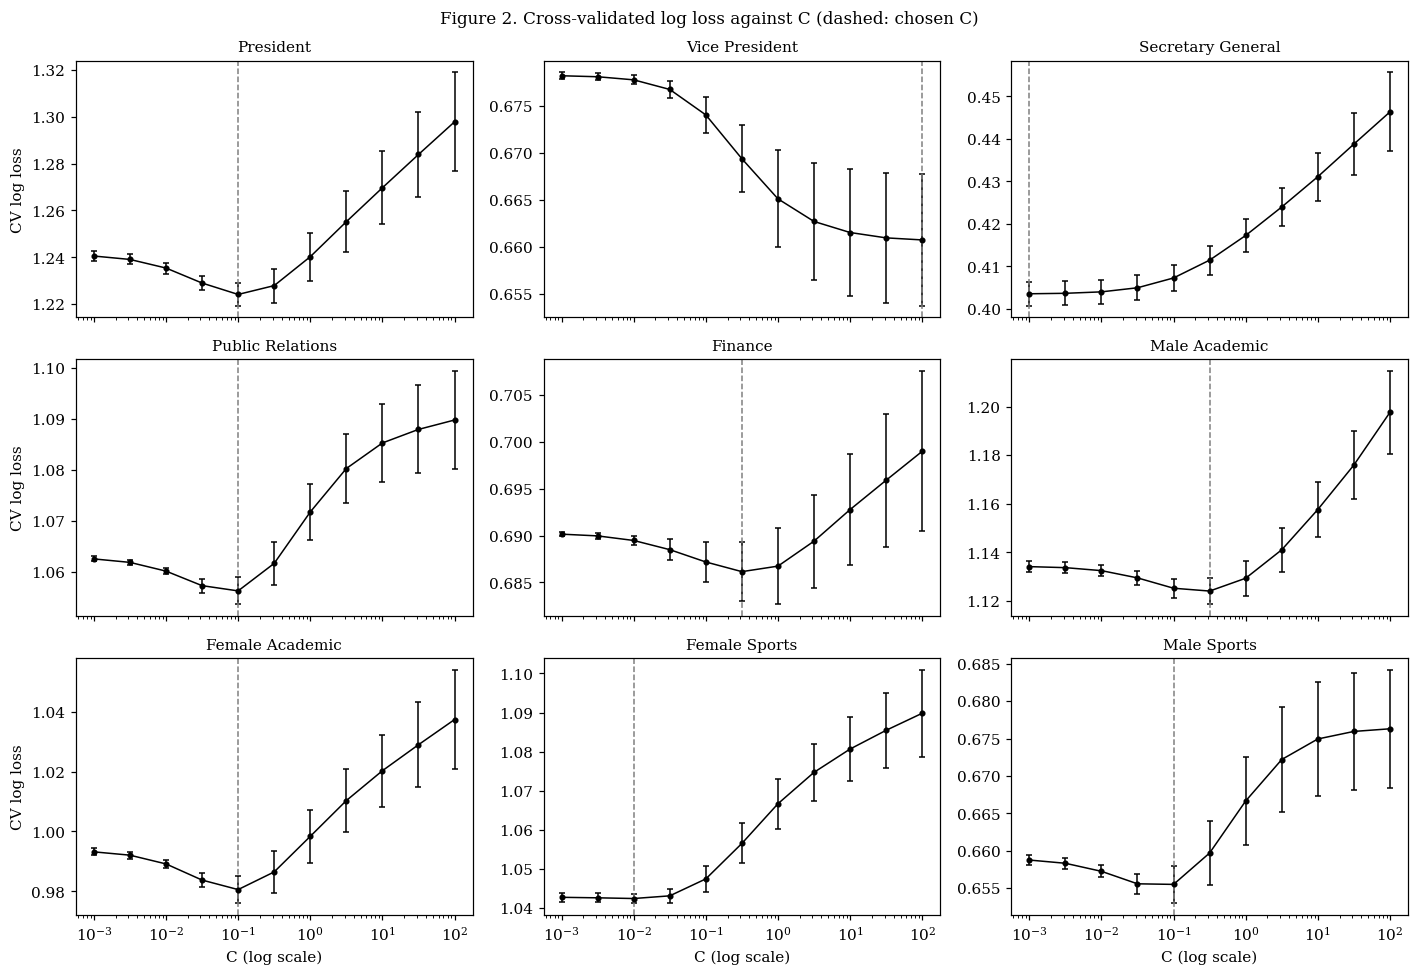

,best_C,cv_log_loss
seat,,
president,0.1000,1.2242
vice_president,100.0000,0.6607
secretary_general,0.0010,0.4036
public_relations,0.1000,1.0563
finance,0.3162,0.6861
male_academic,0.3162,1.1241
female_academic,0.1000,0.9806
female_sports,0.0100,1.0424
male_sports,0.1000,0.6555


In [ ]:
tuned, curves, rows = {}, {}, []
for seat in SEATS:
    X_tr, X_te, y_tr, y_te = splits[seat]
    grid = GridSearchCV(make_lr(), {'model__C': C_GRID}, scoring='neg_log_loss', cv=CV, n_jobs=-1).fit(X_tr, y_tr)
    tuned[seat] = grid.best_params_['model__C']
    curves[seat] = pd.DataFrame(grid.cv_results_)
    rows.append({'seat': seat, 'best_C': tuned[seat], 'cv_log_loss': -grid.best_score_})

fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharex=True)
for ax, seat in zip(axes.flat, SEATS):
    r = curves[seat]
    ax.errorbar(r['param_model__C'].astype(float), -r['mean_test_score'],
                yerr=r['std_test_score'] / np.sqrt(CV.get_n_splits()),
                color='black', marker='o', markersize=3, capsize=2, linewidth=1)
    ax.axvline(tuned[seat], color='0.5', linestyle='--', linewidth=1)
    ax.set_xscale('log')
    ax.set_title(seat.replace('_', ' ').title(), fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel('C (log scale)')
for ax in axes[:, 0]:
    ax.set_ylabel('CV log loss')
fig.suptitle('Figure 2. Cross-validated log loss against C (dashed: chosen C)', fontsize=11)
plt.tight_layout()
plt.show()

pd.DataFrame(rows).set_index('seat').round(4)

- Most seats choose C between 0.01 and 0.32: moderate to strong shrinkage of small schools towards the seat average.
- Secretary General chooses the minimum (0.001), so school is effectively ignored, matching its non-significant test in Observation 3.
- Vice President chooses the maximum (100), keeping the strong STH pattern.

### 4.3 Cross-validated comparison with the baseline

In [ ]:
rows = []
for seat in SEATS:
    X_tr, X_te, y_tr, y_te = splits[seat]
    for name, est in {'Prior baseline': DummyClassifier(strategy='prior'),
                      'Logistic regression': make_lr(tuned[seat])}.items():
        res = cross_validate(est, X_tr, y_tr, cv=CV, scoring='neg_log_loss', n_jobs=-1)
        rows.append({'seat': seat, 'model': name, 'log_loss': -res['test_score'].mean()})

cv_ll = pd.DataFrame(rows).pivot(index='seat', columns='model', values='log_loss').loc[SEATS]
cv_ll['improvement_%'] = 100 * (cv_ll['Prior baseline'] - cv_ll['Logistic regression']) / cv_ll['Prior baseline']
print(f"Logistic regression beats the baseline in {(cv_ll['improvement_%'] > 0).sum()} of {len(SEATS)} seats")
cv_ll.round(4)

Logistic regression beats the baseline in 8 of 9 seats


model,Logistic regression,Prior baseline,improvement_%
seat,,,
president,1.2242,1.2413,1.3806
vice_president,0.6607,0.6783,2.5883
secretary_general,0.4036,0.4035,-0.0129
public_relations,1.0563,1.0629,0.6214
finance,0.6861,0.6902,0.5933
male_academic,1.1241,1.1344,0.9028
female_academic,0.9806,0.9938,1.3220
female_sports,1.0424,1.0428,0.0369
male_sports,0.6555,0.6590,0.5270


The model beats the baseline in 8 of 9 seats. In Secretary General it is equal, since it has shrunk to the baseline. The improvements are small (at most 2.6%), as expected from Observation 3.

### 4.4 test set evaluation

In [ ]:
rows = []
for seat in SEATS:
    X_tr, X_te, y_tr, y_te = splits[seat]
    for name, est in {'Prior baseline': DummyClassifier(strategy='prior'),
                      'Logistic regression': make_lr(tuned[seat])}.items():
        est.fit(X_tr, y_tr)
        proba, pred = est.predict_proba(X_te), est.predict(X_te)
        rows.append({'seat': seat, 'model': name,
                     'log_loss': log_loss(y_te, proba, labels=est.classes_),
                     'accuracy_%': 100 * accuracy_score(y_te, pred),
                     'macro_f1': f1_score(y_te, pred, average='macro', zero_division=0)})

test = pd.DataFrame(rows)
display(test.pivot(index='seat', columns='model', values='log_loss').loc[SEATS].round(4))
test.groupby('model').mean(numeric_only=True).round(4)

model,Logistic regression,Prior baseline
seat,,
president,1.2244,1.2494
vice_president,0.6612,0.6805
secretary_general,0.3875,0.3875
public_relations,1.0495,1.0631
finance,0.6825,0.6905
male_academic,1.1934,1.1309
female_academic,1.0002,0.9993
female_sports,1.0412,1.0468
male_sports,0.6538,0.6626


,log_loss,accuracy_%,macro_f1
model,,,
Logistic regression,0.8771,53.9452,0.3292
Prior baseline,0.8790,55.0725,0.2808


- On unseen data, the model has a lower mean log loss than the baseline (0.8771 against 0.8790), confirming the cross-validation result. It is worse only in Male Academic and Female Academic, where school had no significant effect (Observation 3).
- Accuracy (53.9%) is close to the baseline's (55.1%), while macro-F1 is higher (0.329 against 0.281). Because school is a weak predictor, the model mostly predicts each seat's leader (Figure 3).

### 4.5 Predicted vote share

Each seat's model is refitted on all 342 respondents with its tuned C. The predicted share for candidate $k$ is the average of the school-level probabilities, weighted by each school's share of respondents:

$$\widehat{\text{share}}_k = \sum_{s} W_s \, \hat P(k \mid s)$$

Uncertainty comes from 1,000 bootstrap refits (respondents resampled with replacement): the middle 95% of the refitted shares gives the interval, and the proportion of refits in which a candidate leads gives their win probability.

In [ ]:
N_BOOT = 1000
W = (composition['respondents'] / N).reindex(SCHOOLS)
school_grid = pd.DataFrame({'school': SCHOOLS})

def weighted_shares(model, classes):
    p = pd.DataFrame(model.predict_proba(school_grid), index=SCHOOLS, columns=model.classes_)
    return p.mul(W, axis=0).sum().reindex(classes, fill_value=0.0).to_numpy()

boot_rng = np.random.default_rng(SEED)
rows = []
for seat, (X, y) in datasets.items():
    model = make_lr(tuned[seat]).fit(X, y)
    classes = list(model.classes_)
    point = weighted_shares(model, classes)
    d = pd.DataFrame({'school': X['school'].to_numpy(), 'candidate': y.to_numpy()})
    boot = np.empty((N_BOOT, len(classes)))
    for b in range(N_BOOT):
        counts = (d.iloc[boot_rng.integers(0, len(d), len(d))]
                  .groupby(['school', 'candidate']).size().reset_index(name='w'))
        refit = make_lr(tuned[seat]).fit(counts[['school']], counts['candidate'], model__sample_weight=counts['w'])
        boot[b] = weighted_shares(refit, classes)
    wins = np.bincount(boot.argmax(axis=1), minlength=len(classes)) / N_BOOT
    for j, cand in enumerate(classes):
        rows.append({'seat': seat, 'candidate': cand,
                     'predicted_%': 100 * point[j],
                     'ci_low_%': 100 * np.percentile(boot[:, j], 2.5),
                     'ci_high_%': 100 * np.percentile(boot[:, j], 97.5),
                     'win_probability_%': 100 * wins[j]})

predictions = (pd.DataFrame(rows).sort_values(['seat', 'predicted_%'], ascending=[True, False])
               .set_index(['seat', 'candidate']).reindex(SEATS, level=0))
winners = predictions.reset_index().groupby('seat', sort=False).head(1).set_index('seat')
winners['call'] = pd.cut(winners['win_probability_%'], [0, 80, 95, 101], right=False,
                         labels=['Toss-up', 'Likely', 'Confident'])
winners.round(1)

,candidate,predicted_%,ci_low_%,ci_high_%,win_probability_%,call
seat,,,,,,
president,Will Iha,44.2,39.1,49.1,100.0,Confident
vice_president,Fidel Otieno,58.5,53.8,63.3,100.0,Confident
secretary_general,Fateema Abdul,86.3,82.7,89.8,100.0,Confident
public_relations,Sky Nderitu,45.3,39.6,50.5,99.9,Confident
finance,Caleb Mumo,53.8,48.5,59.3,90.6,Likely
male_academic,Moses Maingi,43.6,38.6,49.1,73.5,Toss-up
female_academic,Shania Omolo,55.5,50.2,60.7,100.0,Confident
female_sports,Chadya Kendi,48.0,42.7,53.0,100.0,Confident
male_sports,Michael Karani,62.9,57.7,67.6,100.0,Confident
